# PC3 - Deep Learning - Notebook 1
### Mucha Alvarez Diego Fabrizio - u202317069

# 01 · Conocer los datos

Vamos a revisar las imágenes de células sanguíneas, contar las clases y preparar
los datos para entrenar. Autor: [nombre y apellidos].

## Preparación

Sube la carpeta `PC3_Deep_Learning` a **Mi unidad** de Google Drive, incluyendo
`data/raw/` con las imágenes descargadas. No hace falta subir `.venv`.
Usaremos esa carpeta en los tres notebooks. Ejecútalos en orden: **01 → 02 → 03**.
Para los notebooks 02 y 03, activa una GPU en Colab.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

%cd /content/drive/MyDrive/PC3_Deep_Learning
%pip install -q -r requirements.txt

ModuleNotFoundError: No module named 'google.colab'

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as MostrarImagen
from src.utils import seed_everything

seed_everything(42)

## Separar entrenamiento y validación

Las imágenes ya están en `data/raw/images/`. Reservamos el 20% de TRAIN para
validación y dejamos TEST como viene. Usamos la semilla 42 para repetir la misma
separación. Las imágenes idénticas de TRAIN se mantienen juntas.

In [2]:
from src.utils import make_manifest, save_figure, CLASSES
from PIL import Image
import os

make_manifest("data/raw", "data/splits", seed=42, validation_fraction=0.2)
datos = pd.read_csv("data/splits/manifest.csv")
os.makedirs("results/tables", exist_ok=True)
display(datos.head())

,path,class,label,source_split,width,height,sha256,split
0,TRAIN/EOSINOPHIL/_0_1169.jpeg,EOSINOPHIL,0,TRAIN,320,240,42e396da7b29c8f01ba7a8f56a960f606dbdb9bcfb003b...,train
1,TRAIN/EOSINOPHIL/_0_1414.jpeg,EOSINOPHIL,0,TRAIN,320,240,85fada6fd061968ce129695543c69e35a0dd52b07de777...,val
2,TRAIN/EOSINOPHIL/_0_207.jpeg,EOSINOPHIL,0,TRAIN,320,240,853f0db2d283c3b55914701f80ff6319f400c9e917da02...,train
3,TRAIN/EOSINOPHIL/_0_2142.jpeg,EOSINOPHIL,0,TRAIN,320,240,76746d06b061ab689f041828b414d655127865697ce422...,train
4,TRAIN/EOSINOPHIL/_0_2370.jpeg,EOSINOPHIL,0,TRAIN,320,240,cd121b1c9d474c097872eff9a99a671aae8a751d136705...,val


## Cantidad de imágenes por clase

Esta tabla muestra cuántas imágenes tenemos para entrenar, validar y evaluar.

split,train,val,test
class,,,
EOSINOPHIL,1998,499,623
LYMPHOCYTE,1986,497,620
MONOCYTE,1982,496,620
NEUTROPHIL,1999,500,624


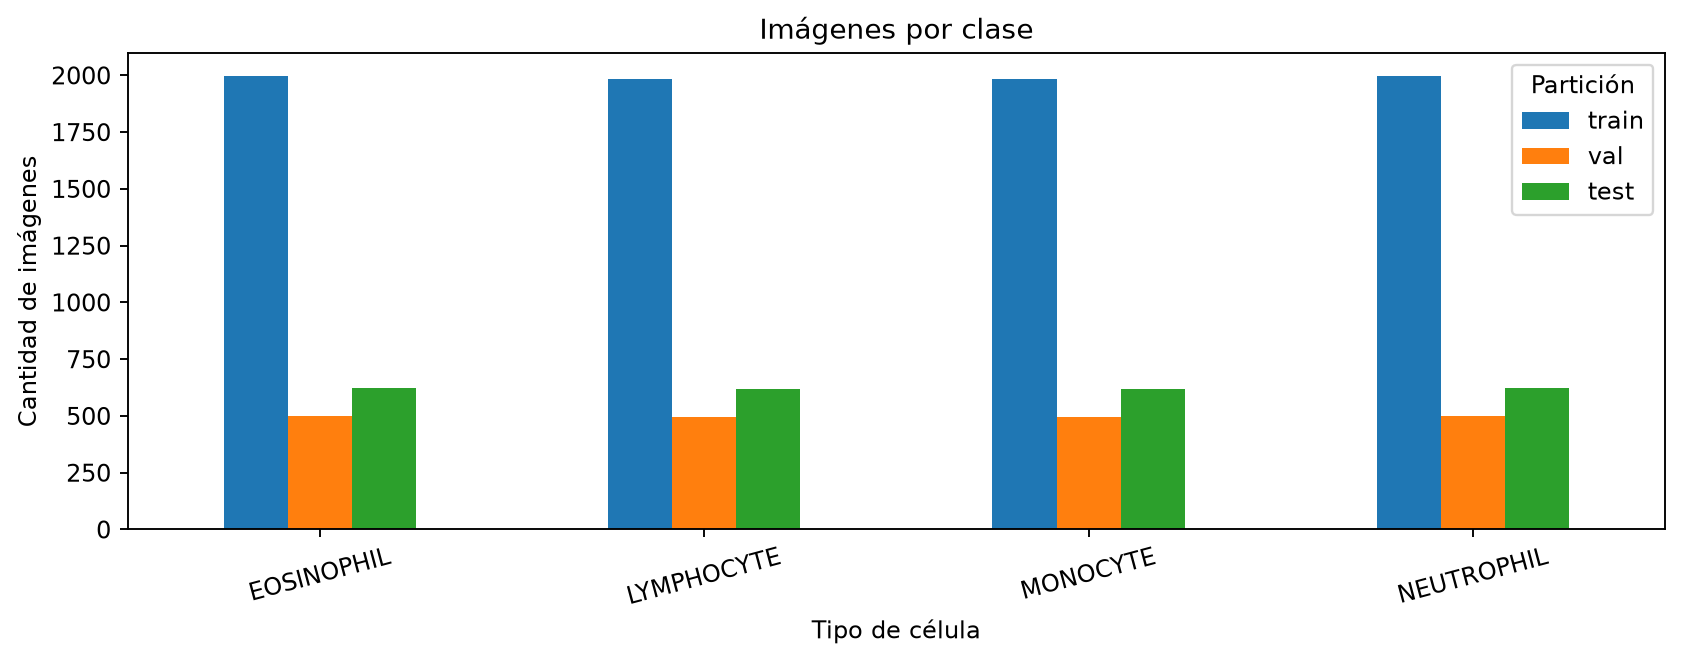

In [3]:
cantidades = datos.groupby(["class", "split"]).size().unstack()
cantidades = cantidades.loc[CLASSES, ["train", "val", "test"]]
cantidades.to_csv("results/tables/class_distribution.csv")
display(cantidades)

cantidades.plot.bar(figsize=(10, 4), rot=15)
plt.title("Imágenes por clase")
plt.xlabel("Tipo de célula")
plt.ylabel("Cantidad de imágenes")
plt.legend(title="Partición")
save_figure(plt.gcf(), "results/figures/eda_class_distribution.png")
display(MostrarImagen(filename="results/figures/eda_class_distribution.png"))

## Ejemplos de las cuatro clases

Mostramos cuatro imágenes de entrenamiento de cada clase.

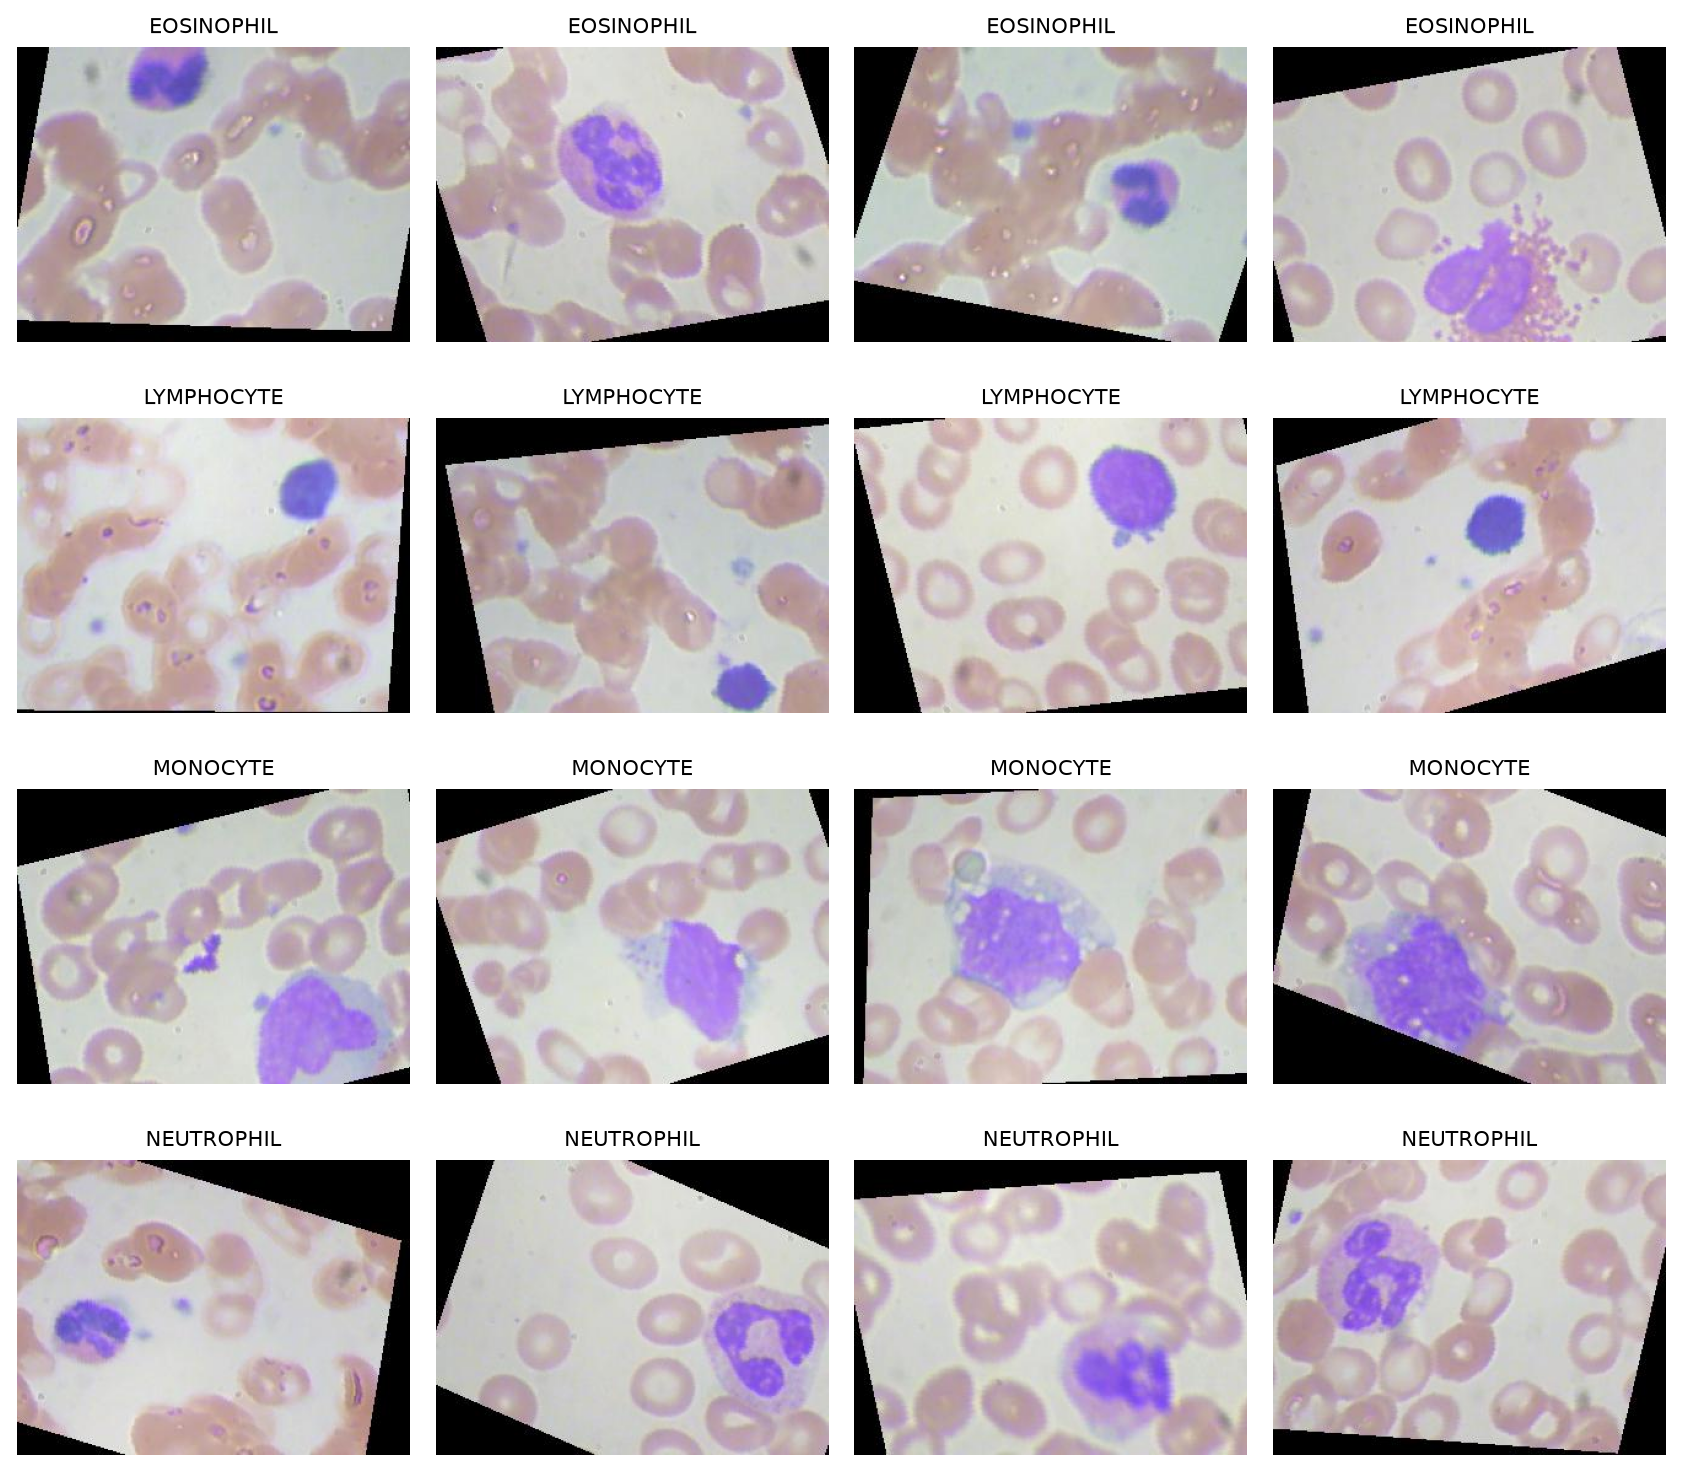

In [4]:
fig, ejes = plt.subplots(4, 4, figsize=(10, 9))
for fila, clase in enumerate(CLASSES):
    ejemplos = datos[(datos["class"] == clase) & (datos["split"] == "train")]
    ejemplos = ejemplos.sample(4, random_state=42)
    for columna, archivo in enumerate(ejemplos["path"]):
        with Image.open("data/raw/images/" + archivo) as imagen:
            ejes[fila, columna].imshow(imagen.convert("RGB"))
        ejes[fila, columna].set_title(clase, fontsize=9)
        ejes[fila, columna].axis("off")
save_figure(fig, "results/figures/eda_examples.png")
display(MostrarImagen(filename="results/figures/eda_examples.png"))

## Tamaño de las imágenes

,width,height,cantidad
0,320,240,12444


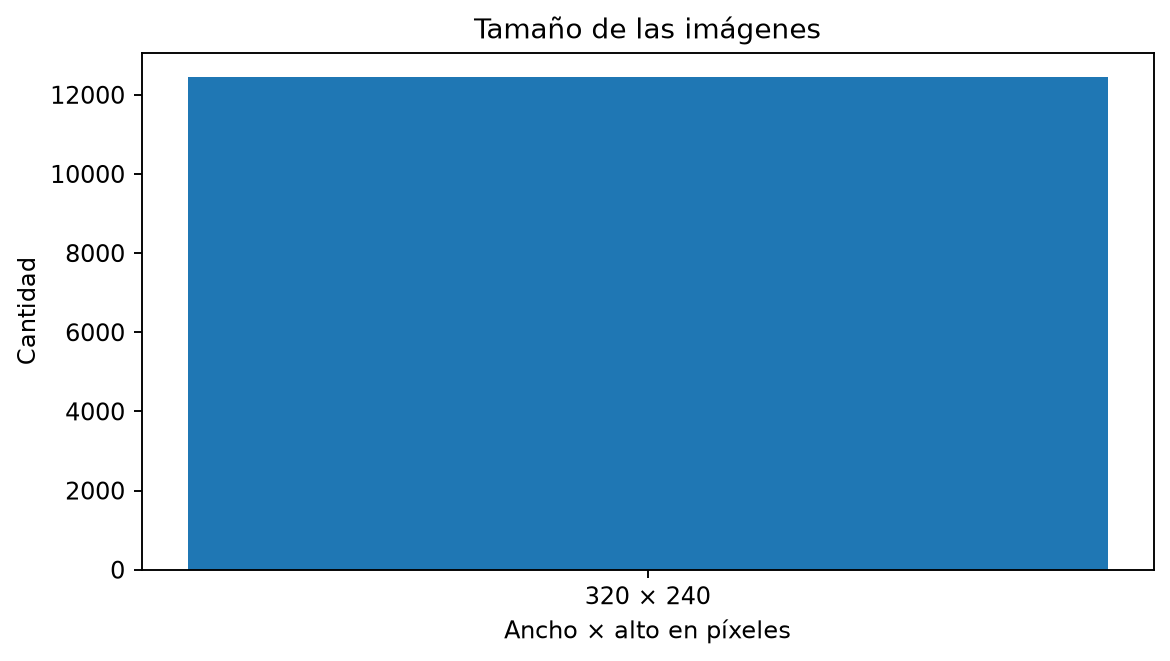

In [5]:
tamanos = datos.groupby(["width", "height"]).size().reset_index(name="cantidad")
tamanos.to_csv("results/tables/image_dimensions.csv", index=False)
display(tamanos)

plt.figure(figsize=(7, 4))
plt.bar(tamanos["width"].astype(str) + " × " + tamanos["height"].astype(str), tamanos["cantidad"])
plt.title("Tamaño de las imágenes")
plt.xlabel("Ancho × alto en píxeles")
plt.ylabel("Cantidad")
save_figure(plt.gcf(), "results/figures/eda_dimensions.png")
display(MostrarImagen(filename="results/figures/eda_dimensions.png"))

## Imágenes repetidas

Revisamos si hay imágenes idénticas. Esta revisión no detecta fotos rotadas ni
permite saber si dos imágenes pertenecen al mismo paciente. Eso limita la evaluación.

In [6]:
with open("data/splits/audit.json") as archivo:
    revision = json.load(archivo)
display(revision)
display(datos[datos.duplicated("sha256", keep=False)][["path", "class", "split"]].head(20))

{'seed': 42,
 'validation_fraction': 0.2,
 'classes': ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL'],
 'rows': 12444,
 'duplicate_images': 0,
 'train_test_shared_hashes': 0,
 'limitation': 'No hay agrupación por paciente ni detección de aumentos de una misma célula.'}

,path,class,split


## Preparación de las imágenes

LeNet y VGG usan imágenes de 64×64. Durante el entrenamiento se aplican giros
y volteos. Validación y test no usan esos cambios. ResNet usará 224×224 y
la normalización de ImageNet. Al cambiar el tamaño se modifica la proporción original.

/home/diegomucha/me/programming/projects/PC3_Deep_Learning/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


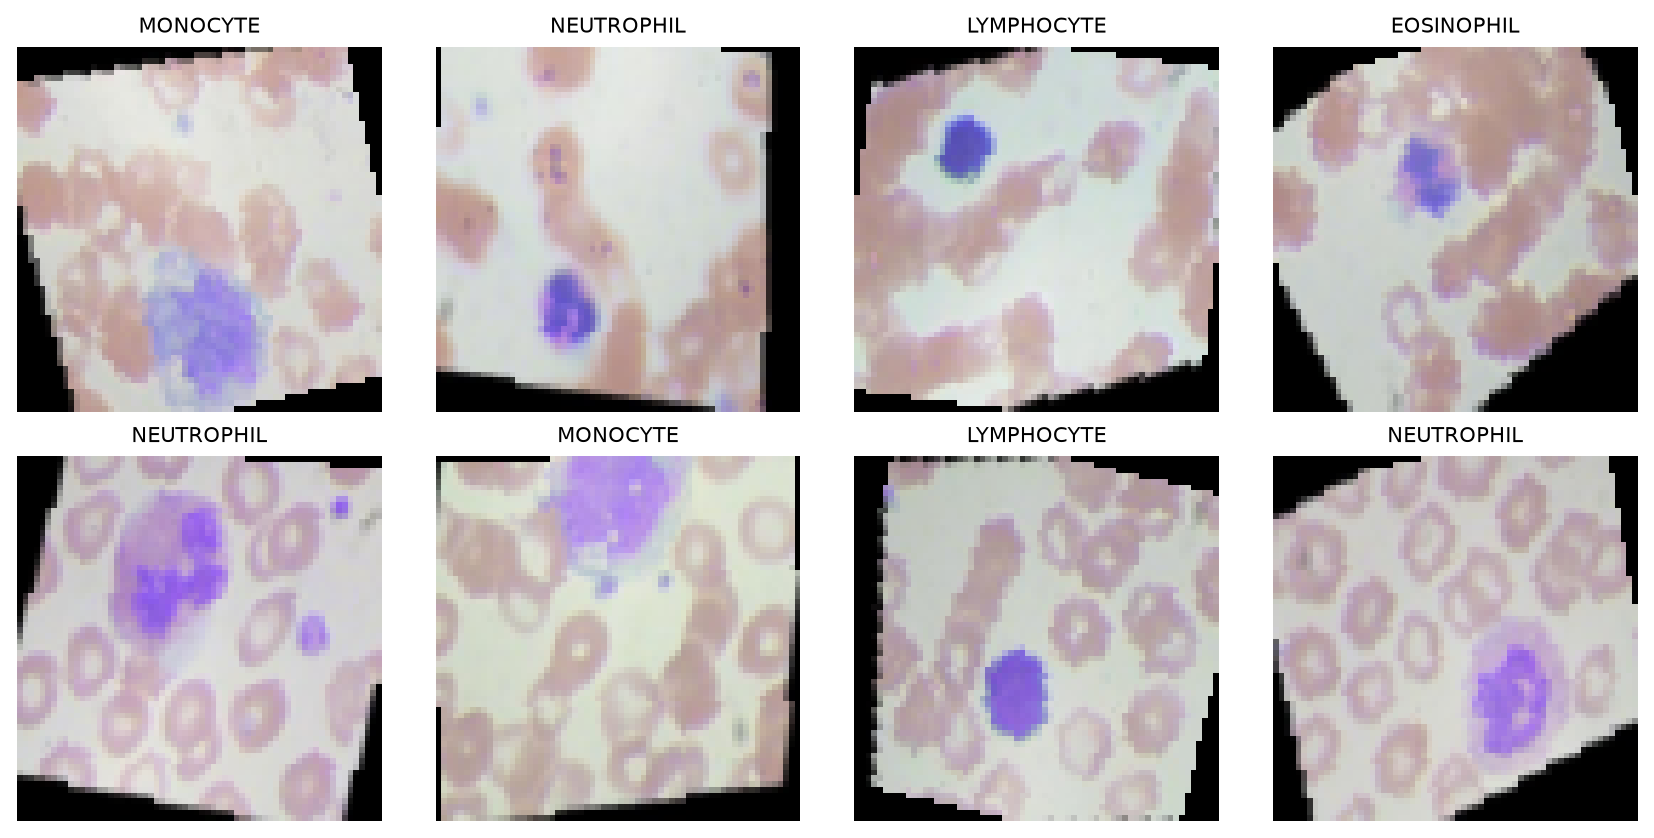

In [7]:
from src.utils import make_loaders
from src.train import DEFAULT_SETTINGS, experiment_plan

cargadores = make_loaders(
    "data/raw/images", "data/splits/manifest.csv",
    experiment_plan(DEFAULT_SETTINGS, "scratch")[0]
)
imagenes, etiquetas = next(iter(cargadores["train"]))

fig, ejes = plt.subplots(2, 4, figsize=(10, 5))
for eje, imagen, etiqueta in zip(ejes.flat, imagenes[:8], etiquetas[:8]):
    eje.imshow((imagen.permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1))
    eje.set_title(CLASSES[int(etiqueta)], fontsize=9)
    eje.axis("off")
save_figure(fig, "results/figures/eda_augmented_batch.png")
display(MostrarImagen(filename="results/figures/eda_augmented_batch.png"))

## Comentarios

**Distribución de clases.** Sí. El conjunto está muy balanceado. En entrenamiento hay entre 1 982 y 1 999 imágenes por clase; en validación, entre 496 y 500; y en test, entre 620 y 624. Cada clase representa aproximadamente el 25% de cada partición. Por ello, accuracy es una métrica útil, aunque se complementará con macro-F1 y recall por clase.

**Diferencias visibles.** Las imágenes tienen fondo claro, glóbulos rojos rosados y la célula de interés en tonos morados o azules. Se observa variación de brillo, enfoque, posición y orientación. Los linfocitos suelen verse pequeños y redondeados, con un núcleo oscuro; los monocitos suelen ser más grandes y de forma menos regular; y los neutrófilos muestran núcleos segmentados. Los eosinófilos presentan una textura más granulada en los ejemplos mostrados. Estas son observaciones visuales del dataset, no un diagnóstico médico.

**Imágenes repetidas.** No se encontraron duplicados exactos: los 12 444 hashes de imagen son distintos y tampoco hay coincidencias entre TRAIN y TEST. Aun así, el análisis por hash no detecta imágenes muy parecidas, rotaciones, cambios de color ni varias imágenes de un mismo paciente. Si existieran esos casos, las métricas podrían ser más optimistas de lo que serían con pacientes completamente nuevos.

Continúa con `02_lenet_vgg.ipynb`.